In [1]:
import torch

SEED = 1234
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

# 0. Choosing "teacher" model

In [2]:
checkpoint = "bert-base-uncased"
task_name  = "stsb"

# 1. Loading our mrpc part of the GLUE dataset

In [3]:
from datasets import load_dataset
from transformers import AutoTokenizer, DataCollatorWithPadding

raw_datasets = load_dataset("glue", task_name)
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
raw_datasets

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 5749
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 1500
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 1379
    })
})

In [5]:
raw_datasets['train']

Dataset({
    features: ['sentence1', 'sentence2', 'label', 'idx'],
    num_rows: 5749
})

In [6]:
from datasets import DatasetDict

In [7]:
raw_datasets = DatasetDict({
    "train": raw_datasets['train'],
    "validation": raw_datasets['validation'],
    "test": raw_datasets['test']
})

In [8]:
raw_datasets

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 5749
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 1500
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 1379
    })
})

In [9]:
raw_train_dataset = raw_datasets["train"]
raw_train_dataset[0]

{'sentence1': 'A plane is taking off.',
 'sentence2': 'An air plane is taking off.',
 'label': 5.0,
 'idx': 0}

In [10]:
raw_train_dataset[5]['sentence1']

'Some men are fighting.'

In [11]:
raw_train_dataset[5]['sentence2']

'Two men are fighting.'

In [12]:
raw_train_dataset[5]['idx']

5

In [13]:
raw_train_dataset.features

{'sentence1': Value('string'),
 'sentence2': Value('string'),
 'label': Value('float32'),
 'idx': Value('int32')}

# 2. Preprocess

In [14]:
def tokenize_function(example):
    return tokenizer(example["sentence1"], example["sentence2"], truncation=True)

tokenized_datasets = raw_datasets.map(tokenize_function, batched=True)
tokenized_datasets

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 5749
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1500
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1379
    })
})

# 3. Preparing for Training

In [15]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

In [16]:
tokenized_datasets = tokenized_datasets.remove_columns(["sentence1", "sentence2", "idx"])
tokenized_datasets = tokenized_datasets.rename_column("label", "labels")
tokenized_datasets.set_format("torch")
tokenized_datasets["train"].column_names

['labels', 'input_ids', 'token_type_ids', 'attention_mask']

In [17]:
from torch.utils.data import DataLoader

train_dataloader = DataLoader(
    tokenized_datasets["train"], shuffle=True, batch_size=32, collate_fn=data_collator
)

val_dataloader = DataLoader(
    tokenized_datasets["validation"], batch_size=32, collate_fn=data_collator
)

eval_dataloader = DataLoader(
    tokenized_datasets["test"], batch_size=32, collate_fn=data_collator
)

In [18]:
for batch in train_dataloader:
    break
{k: v.shape for k, v in batch.items()}

{'labels': torch.Size([32]),
 'input_ids': torch.Size([32, 66]),
 'token_type_ids': torch.Size([32, 66]),
 'attention_mask': torch.Size([32, 66])}

# 4. Loading model

In [19]:
import sys
sys.path.insert(0, '../')

In [20]:
from Bert_model.modeling_bert import BertForSequenceClassification

In [21]:
num_labels = 1

In [22]:
model = BertForSequenceClassification.from_pretrained(
    checkpoint,
    num_labels=num_labels,
    problem_type="regression",
    # id2label=id2label,
    # label2id=label2id,
    output_hidden_states=True,
    output_attentions=True
)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [23]:
model.set_use_module_grafting(False)
model.set_use_scc_status(False)

In [24]:
outputs = model(**batch)
print(outputs.loss, outputs.logits.shape)

tensor(4.9161, grad_fn=<MseLossBackward0>) torch.Size([32, 1])


In [25]:
teacher_model = BertForSequenceClassification.from_pretrained(
    checkpoint,
    num_labels=num_labels,
    problem_type="regression",
    # id2label=id2label,
    # label2id=label2id,
    output_hidden_states=True,
    output_attentions=True
)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [26]:
teacher_model.set_use_module_grafting(False)
teacher_model.set_use_scc_status(False)

In [27]:
outputs = teacher_model(**batch)
print(outputs.loss, outputs.logits.shape)

tensor(10.6868, grad_fn=<MseLossBackward0>) torch.Size([32, 1])


In [28]:
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
model.to(device)
teacher_model.to(device)

device

device(type='cuda')

### Load Trained Weights

In [29]:
load_path = '../glue_fine_tune/weights/'
best_weight = torch.load(load_path + f'bert-{task_name}.pt', map_location=device)
teacher_model.load_state_dict(best_weight['model_state_dict'])

<All keys matched successfully>

In [30]:
from train_eval_func import eval_loop

In [31]:
eval_loop(teacher_model, val_dataloader, task_name, device, regression=True)[0]

{'pearson': 0.900084701022039, 'spearmanr': 0.8962584593578651}

In [32]:
model.load_state_dict(best_weight['model_state_dict'])

<All keys matched successfully>

In [33]:
eval_loop(model, val_dataloader, task_name, device, regression=True)[0]

{'pearson': 0.900084701022039, 'spearmanr': 0.8962584593578651}

In [34]:
from merge_helper import merge_bert_layers

In [35]:
encoder_layers = model.bert.encoder.layer

for layer1_idx in range(len(encoder_layers) - 2, -1, -2):
    layer2_idx = layer1_idx + 1

    print(f"Merging layers {layer1_idx + 1} and {layer2_idx + 1}")

    encoder_layers[layer1_idx] = merge_bert_layers(
        model,
        layer1_idx,
        layer2_idx,
        ln_strategy="use_deeper",
    )

# Remove the second layer of each original pair, in reverse order
for layer2_idx in range(len(encoder_layers) - 1, 0, -2):
    del encoder_layers[layer2_idx]

Merging layers 11 and 12
Merging layers 9 and 10
Merging layers 7 and 8
Merging layers 5 and 6
Merging layers 3 and 4
Merging layers 1 and 2


In [36]:
model.bert.encoder

BertEncoder(
  (layer): ModuleList(
    (0-5): 6 x BertLayer(
      (attention): BertAttention(
        (self): BertSelfAttention(
          (query): Linear(in_features=768, out_features=1536, bias=True)
          (key): Linear(in_features=768, out_features=1536, bias=True)
          (value): Linear(in_features=768, out_features=1536, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (output): BertSelfOutput(
          (dense): Linear(in_features=1536, out_features=768, bias=True)
          (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
      (intermediate): BertIntermediate(
        (dense): Linear(in_features=768, out_features=6144, bias=True)
        (intermediate_act_fn): GELUActivation()
      )
      (output): BertOutput(
        (dense): Linear(in_features=6144, out_features=768, bias=True)
        (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=Tru

In [37]:
eval_loop(model, val_dataloader, task_name, device, regression=True)[0]

{'pearson': 0.7512815537875321, 'spearmanr': 0.7658308961547388}

# 5. Learning Rate and Leanring Scheduler Setup

In [38]:
from torch.optim import AdamW

optimizer = AdamW(model.parameters(), lr=3e-5)

In [39]:
from train_eval_func import set_lr_scheduler

num_epochs = 10
num_training_steps = num_epochs * len(train_dataloader)

lr_scheduler = set_lr_scheduler(
    optimizer          = optimizer,
    num_training_steps = num_training_steps
)

print(num_training_steps)

1800


In [40]:
patience=3
save_path=f'./weights/alt/bert-{task_name}.pt'

# 6. Training

In [41]:
from train_eval_func import train

In [42]:
train_stats = train(
    model,
    train_dataloader,
    val_dataloader,
    task_name,
    device,
    num_epochs=num_epochs,
    lr=lr_scheduler,
    patience=patience,
    use_early_stopping=True,
    optimizer=optimizer,
    lr_scheduler=lr_scheduler,
    save_path=save_path,
    display_epoch_iter=True,
    teacher_model=teacher_model,
    regression=True
)

Training:   0%|          | 0/1800 [00:00<?, ?it/s]

Knowledge distillation used!


/home/abhinavl/work/Layer_Graft/layer-grafting-publication/concatenate_test/../train_eval_func.py:240: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:835.)
  total_loss += float(loss)
Training:  10%|█         | 180/1800 [00:48<06:52,  3.92it/s]

✓ Saved checkpoint (best loss: 0.5599)

<----------------- Epoch 1 ----------------->
Loss: 0.18, Training Metrics:
  pearson: 0.9114
  spearmanr: 0.8976
Validation Loss: 0.56, Validation Metrics:
  pearson: 0.8782
  spearmanr: 0.8738
Elapsed Time: 51.622 sec


Training:  20%|██        | 360/1800 [01:52<05:37,  4.26it/s]  

✓ Saved checkpoint (best loss: 0.5291)

<----------------- Epoch 2 ----------------->
Loss: 0.09, Training Metrics:
  pearson: 0.9554
  spearmanr: 0.9481
Validation Loss: 0.53, Validation Metrics:
  pearson: 0.8814
  spearmanr: 0.8750
Elapsed Time: 51.8681 sec


... (12 outputs left out)

Training:  90%|█████████ | 1620/1800 [08:56<00:44,  4.00it/s]


<----------------- Epoch 9 ----------------->
Loss: 0.03, Training Metrics:
  pearson: 0.9873
  spearmanr: 0.9853
Validation Loss: 0.5, Validation Metrics:
  pearson: 0.8887
  spearmanr: 0.8839
Elapsed Time: 51.546 sec


Training: 100%|██████████| 1800/1800 [10:03<00:00,  2.98it/s]

✓ Saved checkpoint (best loss: 0.5010)

<----------------- Epoch 10 ----------------->
Loss: 0.03, Training Metrics:
  pearson: 0.9882
  spearmanr: 0.9866
Validation Loss: 0.5, Validation Metrics:
  pearson: 0.8901
  spearmanr: 0.8852
Elapsed Time: 51.3053 sec

Total Training Time: 603.35 sec
Chosen Primary Metric: pearson
Best Metric Run: 0.8901


### Plotting Loss

In [43]:
from train_eval_func import plotLoss, plotAccuracy

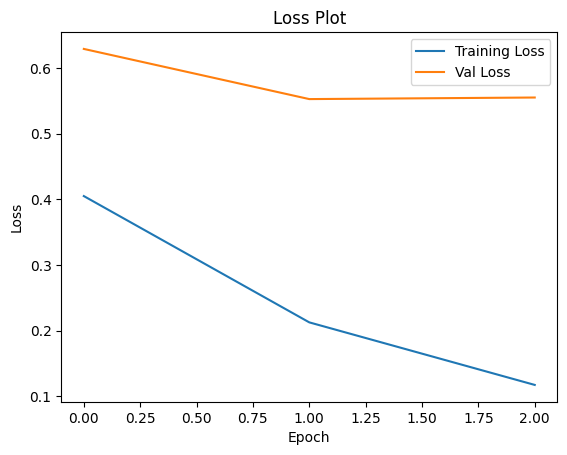

In [44]:
plotLoss(train_stats['train_losses'], train_stats['val_losses'], title="Loss Plot")

### Plotting Accuracy

In [45]:
def getMetricList(train_stats, metric_name='accuracy'):
    train_values = [m[metric_name] for m in train_stats['train_metrics_history']]
    val_values = [m[metric_name] for m in train_stats['val_metrics_history']]

    return train_values, val_values

In [46]:
train_values, val_values = getMetricList(train_stats)

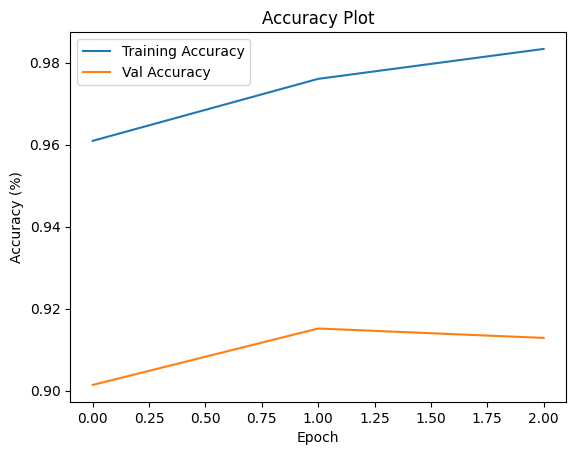

In [47]:
plotAccuracy(train_values, val_values, title="Accuracy Plot")

In [48]:
train_values, val_values = getMetricList(train_stats, 'f1')

KeyError: 'f1'

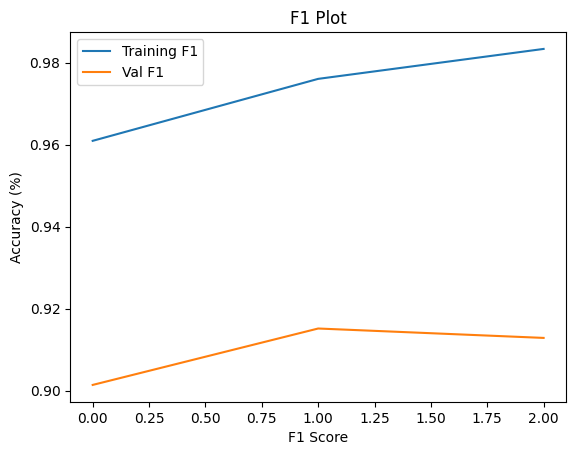

In [49]:
plotAccuracy(train_values, val_values, legend=["Training F1", "Val F1"], title="F1 Plot", xlabel="F1 Score")

# 7. Evaluation

In [50]:
best_weight = torch.load(save_path)

In [51]:
model.load_state_dict(best_weight['model_state_dict'])

<All keys matched successfully>

In [52]:
eval_loop(model, val_dataloader, task_name, device)[0]

{'accuracy': 0.9151376146788991}

In [53]:
best_weight['epoch']

2